# **Regression Practice Notebook**

This notebook contains practice questions for three regression techniques:
1. Simple Linear Regression
2. Multiple Linear Regression
3. Gradient Boosting Regressor

Each section uses a different dataset. Write your code in the empty cells below each question.

## **Section 1: Simple Linear Regression**

**Dataset:** `study_hours_exam_score.csv`
**Shape:** (1000, 2)
**Columns:** `StudyHours` (input), `ExamScore` (output)

**Q1.** Import the required libraries (`pandas`, `matplotlib.pyplot`) and load `study_hours_exam_score.csv` into a DataFrame. Display the first 5 rows.

In [2]:
import pandas as pd
df = pd.read_csv("study_hours_exam_score.csv")
df.head()

,StudyHours,ExamScore
0,5.59,56.64
1,8.92,74.03
2,1.00,25.87
3,4.33,48.35
4,2.61,25.43


**Q2.** Check the shape of the dataset and confirm there are no missing values.

In [3]:
# Shape of the dataset
print(df.shape)

# Missing values by column
print(df.isnull().sum())

# Total missing values
print(df.isnull().sum().sum())

(1000, 2)
StudyHours    0
ExamScore     0
dtype: int64
0


**Q3.** Create a scatter plot to visualize the relationship between `StudyHours` and `ExamScore`.

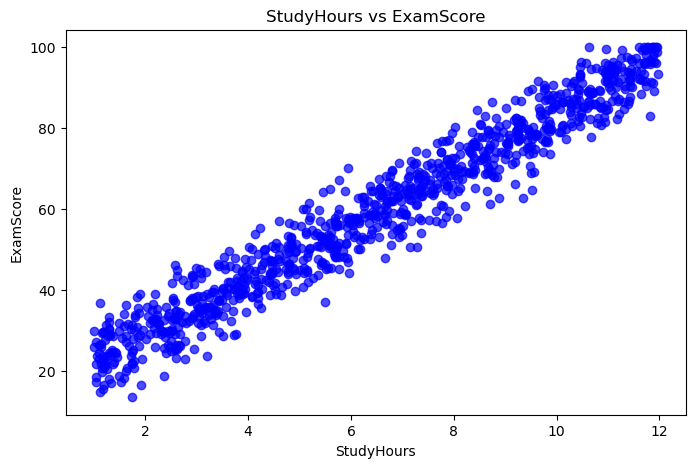

In [4]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
plt.scatter(df['StudyHours'], df['ExamScore'], color='blue', alpha=0.7)
plt.title('StudyHours vs ExamScore')
plt.xlabel('StudyHours')
plt.ylabel('ExamScore')

plt.show()

**Q4.** Separate the dataset into an independent variable `X` and a dependent variable `y`.

In [5]:
X=df[["StudyHours"]]#independent
y=df[["ExamScore"]]#dependent

**Q5.** Split the data into training and testing sets.

In [6]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y)

**Q6.** Build a Simple Linear Regression model and train it using the training data.

In [8]:
from sklearn.linear_model import LinearRegression
lin = LinearRegression()
lin.fit(X_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


**Q7.** Print the slope and intercept of the fitted regression line.

In [11]:
lin.coef_#slope(m)

array([[6.80790914]])

In [12]:
lin.intercept_#intercept(c)

array([15.17598445])

**Q8.** Predict `ExamScore` values for the test set.

In [13]:
predicted_value = lin.predict(X_test)
predicted_value

array([[86.72710955],
       [35.19123733],
       [55.81920204],
       [77.94490676],
       [61.33360844],
       [44.44999377],
       [45.40310105],
       [57.7254166 ],
       [61.46976663],
       [65.48643302],
       [50.91750745],
       [32.2638364 ],
       [67.93728031],
       [76.51524583],
       [40.43332737],
       [27.97485364],
       [70.59236488],
       [79.44264677],
       [91.22032959],
       [89.79066867],
       [64.60140483],
       [70.79660215],
       [23.34547542],
       [64.60140483],
       [65.55451211],
       [89.45027321],
       [25.31976907],
       [30.15338457],
       [73.86016127],
       [94.14773052],
       [36.55281916],
       [52.55140565],
       [22.18813087],
       [78.82993494],
       [93.12654415],
       [90.81185504],
       [91.49264595],
       [33.69349732],
       [55.68304385],
       [75.01750582],
       [85.22936954],
       [27.70253727],
       [81.48501951],
       [32.12767822],
       [62.89942755],
       [82

**Q9.** Calculate the model's training score and testing score.

In [14]:
lin.score(X_train,y_train)

0.9462002015163729

In [15]:
lin.score(X_test,y_test)#test Score ar Model Efficiency

0.9525704938335374

**Q10.** Calculate the error between the actual and predicted values for the test set.

In [16]:
error = y_test-predicted_value
error

,ExamScore
264,-1.537110
220,-9.921237
915,-11.539202
582,1.265093
986,0.696392
...,...
329,-1.540839
351,-0.797562
232,1.682664
452,-5.380669


**Q11.** Plot the actual test values and the predicted values, along with the best fit line.

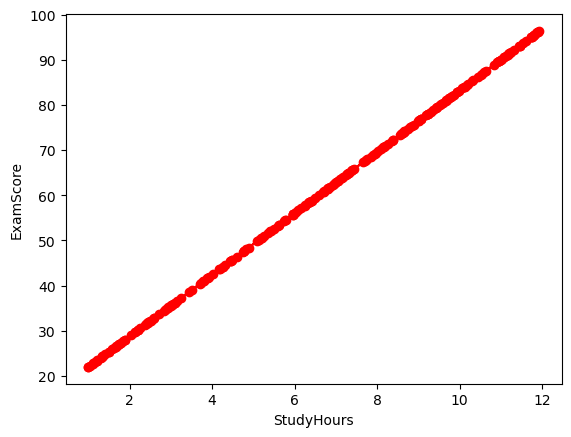

In [18]:
plt.xlabel("StudyHours")
plt.ylabel("ExamScore")
plt.scatter(X_test,predicted_value,color="red",marker="o")
plt.plot(X_test,predicted_value,color="red")

## **Section 2: Multiple Linear Regression**

**Dataset:** `car_price_multiple.csv`
**Shape:** (5000, 4)
**Columns:** `EngineSize_L`, `Mileage_km`, `CarAge_years` (inputs), `Price_USD` (output)

**Q1.** Load `car_price_multiple.csv` into a DataFrame and display its structure (`.info()` and `.describe()`).

In [23]:
df1 = pd.read_csv("car_price_multiple.csv")
df1

,EngineSize_L,Mileage_km,CarAge_years,Price_USD
0,2.31,118374.0,0.7,27190.09
1,1.08,134437.0,3.9,15215.58
2,2.65,6908.0,12.9,22430.60
3,2.31,66733.0,12.7,19368.15
4,2.26,143137.0,4.2,22013.22
...,...,...,...,...
4995,1.31,153154.0,3.7,17945.60
4996,3.34,44333.0,3.8,29196.96
4997,2.98,146968.0,13.7,16567.93
4998,1.41,154746.0,6.1,15665.44


In [24]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   EngineSize_L  5000 non-null   float64
 1   Mileage_km    5000 non-null   float64
 2   CarAge_years  5000 non-null   float64
 3   Price_USD     5000 non-null   float64
dtypes: float64(4)
memory usage: 156.4 KB


In [25]:
df1.describe()

,EngineSize_L,Mileage_km,CarAge_years,Price_USD
count,5000.000000,5000.000000,5000.000000,5000.000000
mean,2.479148,99139.685200,7.535080,22119.486528
std,0.863222,58459.517416,4.326138,5432.659758
min,1.000000,514.000000,0.000000,5820.000000
25%,1.730000,49123.750000,3.800000,18313.570000
50%,2.450000,98220.500000,7.600000,22155.370000
75%,3.220000,151056.000000,11.300000,26030.527500
max,4.000000,199984.000000,15.000000,37912.650000


**Q2.** Confirm the dataset has no missing or duplicate values.

In [26]:
# Shape of the dataset
print(df1.shape)

# Missing values by column
print(df1.isnull().sum())

# Total missing values
print(df1.isnull().sum().sum())

(5000, 4)
EngineSize_L    0
Mileage_km      0
CarAge_years    0
Price_USD       0
dtype: int64
0


**Q3.** Separate the independent variables `X` (`EngineSize_L`, `Mileage_km`, `CarAge_years`) and the dependent variable `y` (`Price_USD`).

In [27]:
X = df[['EngineSize_L', 'Mileage_km', 'CarAge_years']]
y = df[['Price_USD']]

**Q4.** Split the dataset into training and testing sets using an 80-20 split.

In [28]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(4000, 3)
(1000, 3)
(4000, 1)
(1000, 1)


**Q5.** Build and train a Multiple Linear Regression model on the training data.

In [29]:
from sklearn.linear_model import LinearRegression
Multi_lin = LinearRegression()
Multi_lin.fit(X_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


**Q6.** Predict `Price_USD` for the test set.

In [30]:
predicted_value = Multi_lin.predict(X_test)
predicted_value

array([[33355.49799519],
       [17592.37783503],
       [22045.37110939],
       [19574.50689369],
       [28858.8291162 ],
       [28719.12072644],
       [23585.51709274],
       [23200.78640071],
       [23329.26103114],
       [27747.11098179],
       [16553.69723365],
       [12087.36619499],
       [25967.11492707],
       [25873.2593918 ],
       [24307.39899442],
       [18797.7980713 ],
       [22711.15575089],
       [16757.65764429],
       [ 9728.32801776],
       [13547.45169128],
       [20118.60949119],
       [27310.84055028],
       [18820.97533428],
       [19797.13007956],
       [20159.98013759],
       [16732.11919688],
       [20899.35477376],
       [21338.70520965],
       [23108.64635451],
       [30009.93748574],
       [16842.28334171],
       [24150.90090584],
       [19806.28394982],
       [11652.97655884],
       [22233.17972809],
       [24296.34688771],
       [23005.98688505],
       [25716.24562555],
       [29495.74031399],
       [27306.78055956],


**Q7.** Print the model's coefficients and intercept. Identify which feature has the strongest influence based on coefficient magnitude.

In [31]:
Multi_lin.coef_#slope(m)

array([[ 3.24016484e+03, -4.52294121e-02, -8.45089699e+02]])

In [32]:
Multi_lin.intercept_#intercept(c)

array([24936.43909674])

**Q8.** Calculate the training score and testing score of the model.

In [33]:
Multi_lin.score(X_train,y_train)#training accuracy

0.924055892682378

In [34]:
Multi_lin.score(X_test,y_test)#test Score ar Model Efficiency

0.9198906995668753

**Q9.** Compute MAE, MSE, RMSE, and R² score for the model's predictions.

In [37]:
import numpy as np
from sklearn.metrics import *
MSE = mean_squared_error(y_test,predicted_value)
MAE = mean_absolute_error(y_test,predicted_value)
RMSE = (MSE)**(1/2)
r_square = r2_score(y_test,predicted_value)

In [38]:
print(np.round(MSE,2))
print(np.round(MAE,2))
print(np.round(RMSE,2))
print(r_square)

2358416.64
1221.32
1535.71
0.9198906995668753


**Q10.** Create a scatter plot of Actual vs Predicted prices, with a diagonal reference line representing perfect predictions.

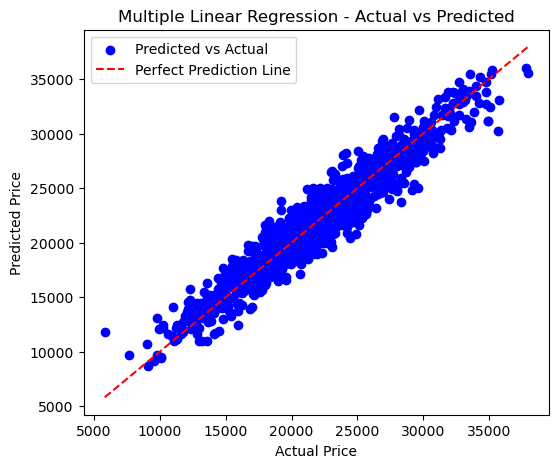

In [39]:
y_pred = Multi_lin.predict(X_test)

plt.figure(figsize=(6,5))
plt.scatter(y_test, y_pred, color='blue', label='Predicted vs Actual')

plt.plot([y_test.min(), y_test.max()],[y_test.min(), y_test.max()],
         color='red', linestyle='--', label='Perfect Prediction Line')

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Multiple Linear Regression - Actual vs Predicted")
plt.legend()
plt.show()

## **Section 3: Gradient Boosting Regressor**

**Dataset:** `laptop_price_gbr.csv`
**Shape:** (10000, 6)
**Columns:** `RAM_GB`, `Storage_GB`, `ScreenSize_inch`, `Weight_kg`, `BatteryLife_hrs` (inputs), `Price_USD` (output)

**Q1.** Load `laptop_price_gbr.csv` into a DataFrame. Check its shape and data types.

In [41]:
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
df2 = pd.read_csv("laptop_price_gbr.csv")
print("Dataset Shape:", df2.shape)
print("\nData Types:")
print(df2.dtypes)

Dataset Shape: (10000, 6)

Data Types:
RAM_GB               int64
Storage_GB           int64
ScreenSize_inch    float64
Weight_kg          float64
BatteryLife_hrs    float64
Price_USD          float64
dtype: object


In [44]:
df2

,RAM_GB,Storage_GB,ScreenSize_inch,Weight_kg,BatteryLife_hrs,Price_USD
0,16,2048,13.0,1.17,16.0,1365.85
1,4,256,12.6,2.44,7.5,371.03
2,8,1024,16.0,1.60,13.5,686.07
3,32,1024,14.1,2.68,10.8,1164.84
4,4,1024,15.2,1.37,9.7,622.77
...,...,...,...,...,...,...
9995,4,256,17.2,1.20,8.7,323.50
9996,4,2048,11.6,1.62,5.9,1022.11
9997,16,1024,13.1,1.78,15.5,955.66
9998,32,1024,13.8,0.96,4.5,1144.20


**Q2.** Confirm the dataset has no missing values.

In [42]:
# Shape of the dataset
print(df2.shape)

# Missing values by column
print(df2.isnull().sum())

# Total missing values
print(df2.isnull().sum().sum())

(10000, 6)
RAM_GB             0
Storage_GB         0
ScreenSize_inch    0
Weight_kg          0
BatteryLife_hrs    0
Price_USD          0
dtype: int64
0


**Q3.** Separate the independent variables `X` and the dependent variable `y` (`Price_USD`).

In [45]:
X = df2[['RAM_GB','Storage_GB','ScreenSize_inch','Weight_kg','BatteryLife_hrs']]
y = df2[['Price_USD']]  

**Q4.** Split the dataset into training and testing sets (80-20 split, `random_state=42`).

In [46]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

**Q5.** Build a `GradientBoostingRegressor` model with `n_estimators=100`, `learning_rate=0.1`, and `max_depth=3`. Train it on the training data.

In [48]:
from sklearn.ensemble import GradientBoostingRegressor
gbr = GradientBoostingRegressor(
    n_estimators=100, #number of trees
    learning_rate=0.1, #how much each tree corrects the previous one
    max_depth=3, #how complex each tree is allowed to be
    random_state=42
)
gbr.fit(X_train,y_train)

,loss,'squared_error'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


**Q6.** Predict `Price_USD` for the test set.

In [49]:
y_pred = gbr.predict(X_test)
y_pred

array([ 300.4783699 , 1577.02005322,  534.85220537, ...,  794.42781271,
        589.32449099,  562.56681571], shape=(2000,))

**Q7.** Evaluate the model using MAE, MSE, RMSE, and R² score.

In [50]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
import numpy as np

mae = mean_absolute_error(y_test,y_pred)
mse = mean_squared_error(y_test,y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test,y_pred)

print("MAE:",round(mae,2))
print("RMSE:",round(rmse,2))
print("R Squared Score:",round(r2,4))

MAE: 48.85
RMSE: 61.03
R Squared Score: 0.9842


**Q8.** Create a scatter plot comparing Actual vs Predicted prices, with a diagonal reference line for perfect predictions.

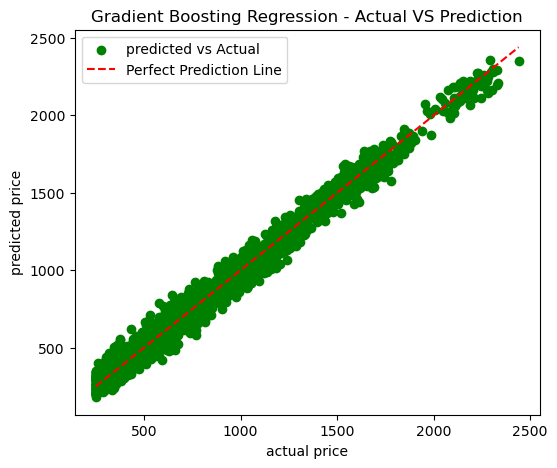

In [51]:
plt.figure(figsize=(6,5))
plt.scatter(y_test,y_pred,color='green',label='predicted vs Actual')
plt.plot([y_test.min(),y_test.max()],[y_test.min(),y_test.max()],
         color='red',linestyle='--',label='Perfect Prediction Line')
plt.xlabel("actual price")
plt.ylabel("predicted price")
plt.title("Gradient Boosting Regression - Actual VS Prediction")
plt.legend()
plt.show()

**Q9.** Extract and plot the feature importances from the trained model. Which feature contributes most to predicting `Price_USD`?

           Feature  Importance
0           RAM_GB    0.686909
1       Storage_GB    0.276293
3        Weight_kg    0.014767
4  BatteryLife_hrs    0.013139
2  ScreenSize_inch    0.008891


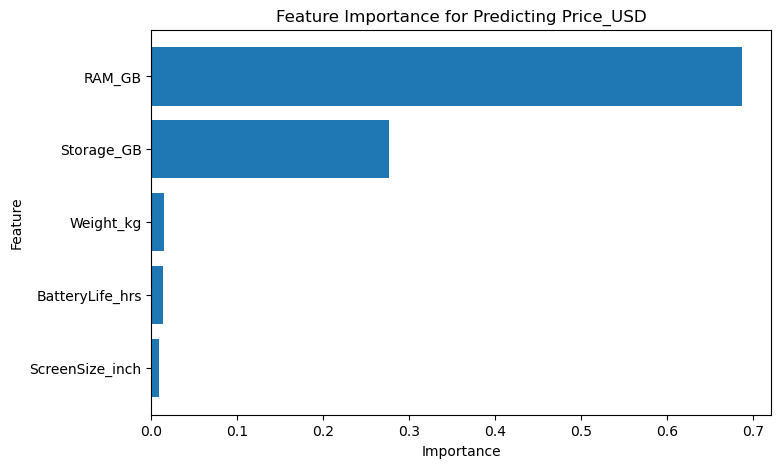

In [57]:
import pandas as pd
import matplotlib.pyplot as plt

# Extract feature importances
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': gbr.feature_importances_
})
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)
print(feature_importance)
plt.figure(figsize=(8,5))
plt.barh(feature_importance['Feature'],
         feature_importance['Importance'])
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Feature Importance for Predicting Price_USD')
plt.gca().invert_yaxis()
plt.show()

**Q10.** Compare the R² score of this model with the Multiple Linear Regression model from Section 2 (conceptually) — which type of model would you expect to perform better on non-linear relationships, and why?

### Q10. Comparison of R² Scores (Conceptual)

The **Gradient Boosting Regression** model is generally expected to achieve a higher **R² score** than the **Multiple Linear Regression** model when the relationship between the features and **Price_USD** is non-linear.

**Why?**

- **Multiple Linear Regression** assumes a linear relationship between the independent variables and the target variable. It fits a single linear equation to the data and may struggle to capture complex patterns.
- **Gradient Boosting Regression** is an ensemble technique that builds multiple decision trees sequentially, allowing it to learn non-linear relationships and feature interactions more effectively.

**Conclusion:**

> For datasets with non-linear relationships, **Gradient Boosting Regression** is expected to perform better than **Multiple Linear Regression** and achieve a higher **R² score** because it can model complex patterns and interactions among features that a linear model cannot capture.